In [5]:
import pandas as pd
df = pd.read_csv("c:\\Users\\gupta\\Downloads\\creditcard.csv\\creditcard.csv")
df.head()
df.shape

(284807, 31)

In [7]:
df.shape
df.info()
df["Class"].value_counts()
df.duplicated().sum()
df.shape
df.info()
df["Class"].value_counts()
df[df.duplicated()].head()
df_clean = df.drop_duplicates()
df_clean.shape
df_clean["Class"].value_counts()
df_clean.duplicated().sum()
df_clean.to_csv("../data/creditcard_clean.csv", index=False)


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

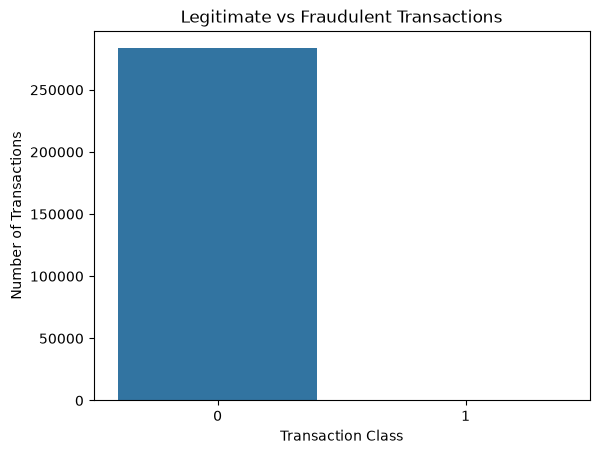

Class
0     88.413575
1    123.871860
Name: Amount, dtype: float64

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x="Class", data=df_clean)
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.title("Legitimate vs Fraudulent Transactions")
plt.show()
df_clean["Amount"].describe()
df_clean.groupby("Class")["Amount"].mean()



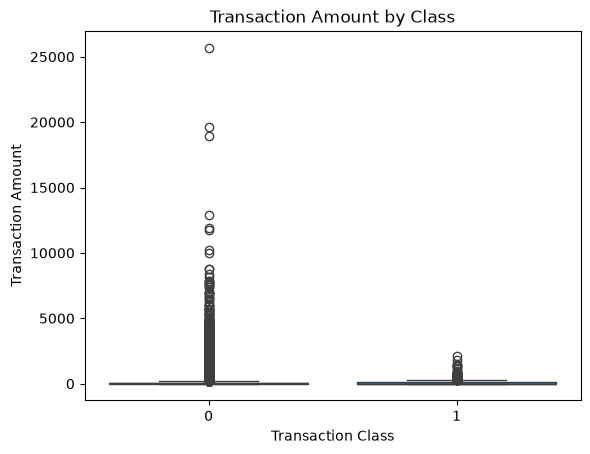

In [9]:
sns.boxplot(x="Class", y="Amount", data=df_clean)
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount by Class")
plt.show()


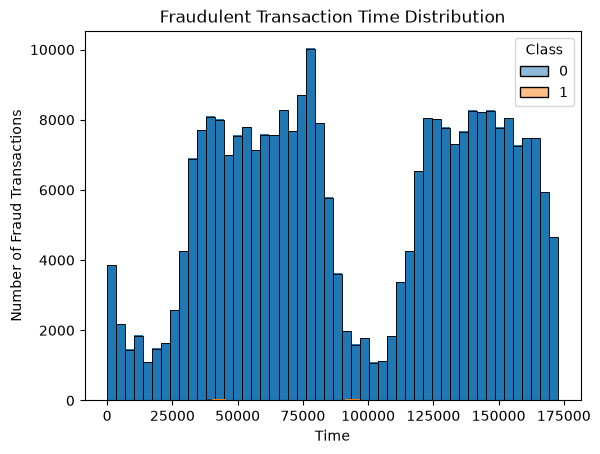

In [12]:
plt.hist(df_clean["Time"], bins=50)

plt.xlabel("Time")
plt.ylabel("Number of Transactions")
plt.title("Transaction Time Distribution")
sns.histplot(
    data=df_clean,
    x="Time",
    hue="Class",
    bins=50
)

plt.xlabel("Time")
plt.ylabel("Number of Transactions")
plt.title("Transaction Time Distribution by Class")

fraud = df_clean[df_clean["Class"] == 1]

plt.hist(fraud["Time"], bins=30)

plt.xlabel("Time")
plt.ylabel("Number of Fraud Transactions")
plt.title("Fraudulent Transaction Time Distribution")


plt.show()


In [14]:
import sklearn 
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train, y_train)
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

[[55262  1389]
 [   12    83]]


In [19]:
import joblib

joblib.dump(model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model saved successfully!")


model = joblib.load("fraud_model.pkl")
scaler = joblib.load("scaler.pkl")

sample = [[10000, -1.2, 0.5, 1.1, -0.3, 0.2, -0.4, 0.1,
           -0.2, 0.3, -0.1, 0.5, -0.2, 0.1, 0.3, -0.4,
           0.2, -0.1, 0.4, -0.3, 0.2, 0.1, -0.2, 0.3,
           -0.1, 0.2, -0.3, 0.1, 0.5, 100]]

sample_scaled = scaler.transform(sample)

prediction = model.predict(sample_scaled)

if prediction[0] == 1:
    print("Fraudulent Transaction")
else:
    print("Legitimate Transaction")



Model saved successfully!
Legitimate Transaction


c:\Users\gupta\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd
import joblib

model = joblib.load("fraud_model.pkl")
scaler = joblib.load("scaler.pkl")

sample = pd.DataFrame([[
    10000, -1.2, 0.5, 1.1, -0.3, 0.2, -0.4, 0.1,
    -0.2, 0.3, -0.1, 0.5, -0.2, 0.1, 0.3, -0.4,
    0.2, -0.1, 0.4, -0.3, 0.2, 0.1, -0.2, 0.3,
    -0.1, 0.2, -0.3, 0.1, 0.5, 100
]], columns=[
    "Time", "V1", "V2", "V3", "V4", "V5", "V6", "V7",
    "V8", "V9", "V10", "V11", "V12", "V13", "V14", "V15",
    "V16", "V17", "V18", "V19", "V20", "V21", "V22", "V23",
    "V24", "V25", "V26", "V27", "V28", "Amount"
])

sample_scaled = scaler.transform(sample)

prediction = model.predict(sample_scaled)

if prediction[0] == 1:
    print("🚨 Fraudulent Transaction")
else:
    print("✅ Legitimate Transaction")

print("Actual:", actual)
print("Predicted:", prediction[0])


✅ Legitimate Transaction


In [22]:
# Select one transaction from your existing dataframe
sample = df_clean.drop("Class", axis=1).iloc[[0]]

# Actual result
actual = df_clean["Class"].iloc[0]

# Scale
sample_scaled = scaler.transform(sample)

# Predict
prediction = model.predict(sample_scaled)

print("Actual:", actual)
print("Predicted:", prediction[0])

if prediction[0] == 1:
    print("🚨 Fraudulent Transaction")
else:
    print("✅ Legitimate Transaction")

Actual: 0
Predicted: 0
✅ Legitimate Transaction


In [23]:
# Test an actual fraud transaction
fraud_sample = df_clean[df_clean["Class"] == 1].drop("Class", axis=1).iloc[[0]]

actual = 1

fraud_scaled = scaler.transform(fraud_sample)
prediction = model.predict(fraud_scaled)

print("Actual:", actual)
print("Predicted:", prediction[0])

if prediction[0] == 1:
    print("🚨 Fraudulent Transaction")
else:
    print("✅ Legitimate Transaction")
    

Actual: 1
Predicted: 1
🚨 Fraudulent Transaction
